In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="whitegrid")
from sklearn.preprocessing import MinMaxScaler
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models

In [4]:

file_path = 'cardio_train.csv'
data = pd.read_csv(file_path)

data.head()


,id;age;gender;height;weight;ap_hi;ap_lo;cholesterol;gluc;smoke;alco;active;cardio
0,0;18393;2;168;62.0;110;80;1;1;0;0;1;0
1,1;20228;1;156;85.0;140;90;3;1;0;0;1;1
2,2;18857;1;165;64.0;130;70;3;1;0;0;0;1
3,3;17623;2;169;82.0;150;100;1;1;0;0;1;1
4,4;17474;1;156;56.0;100;60;1;1;0;0;0;0


In [5]:
data = pd.read_csv(file_path, delimiter=';')

data.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [6]:
missing_values = data.isnull().sum()
data_types = data.dtypes

missing_values, data_types

(id             0
 age            0
 gender         0
 height         0
 weight         0
 ap_hi          0
 ap_lo          0
 cholesterol    0
 gluc           0
 smoke          0
 alco           0
 active         0
 cardio         0
 dtype: int64,
 id               int64
 age              int64
 gender           int64
 height           int64
 weight         float64
 ap_hi            int64
 ap_lo            int64
 cholesterol      int64
 gluc             int64
 smoke            int64
 alco             int64
 active           int64
 cardio           int64
 dtype: object)

In [31]:
X.columns

Index(['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol',
       'gluc', 'smoke', 'alco', 'active'],
      dtype='object')

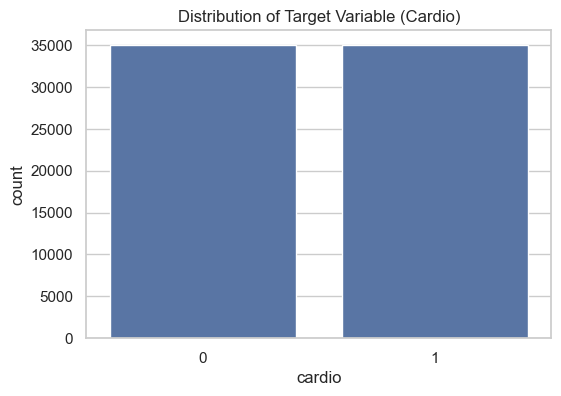

In [7]:
plt.figure(figsize=(6, 4))
sns.countplot(x='cardio', data=data)
plt.title('Distribution of Target Variable (Cardio)')
plt.show()


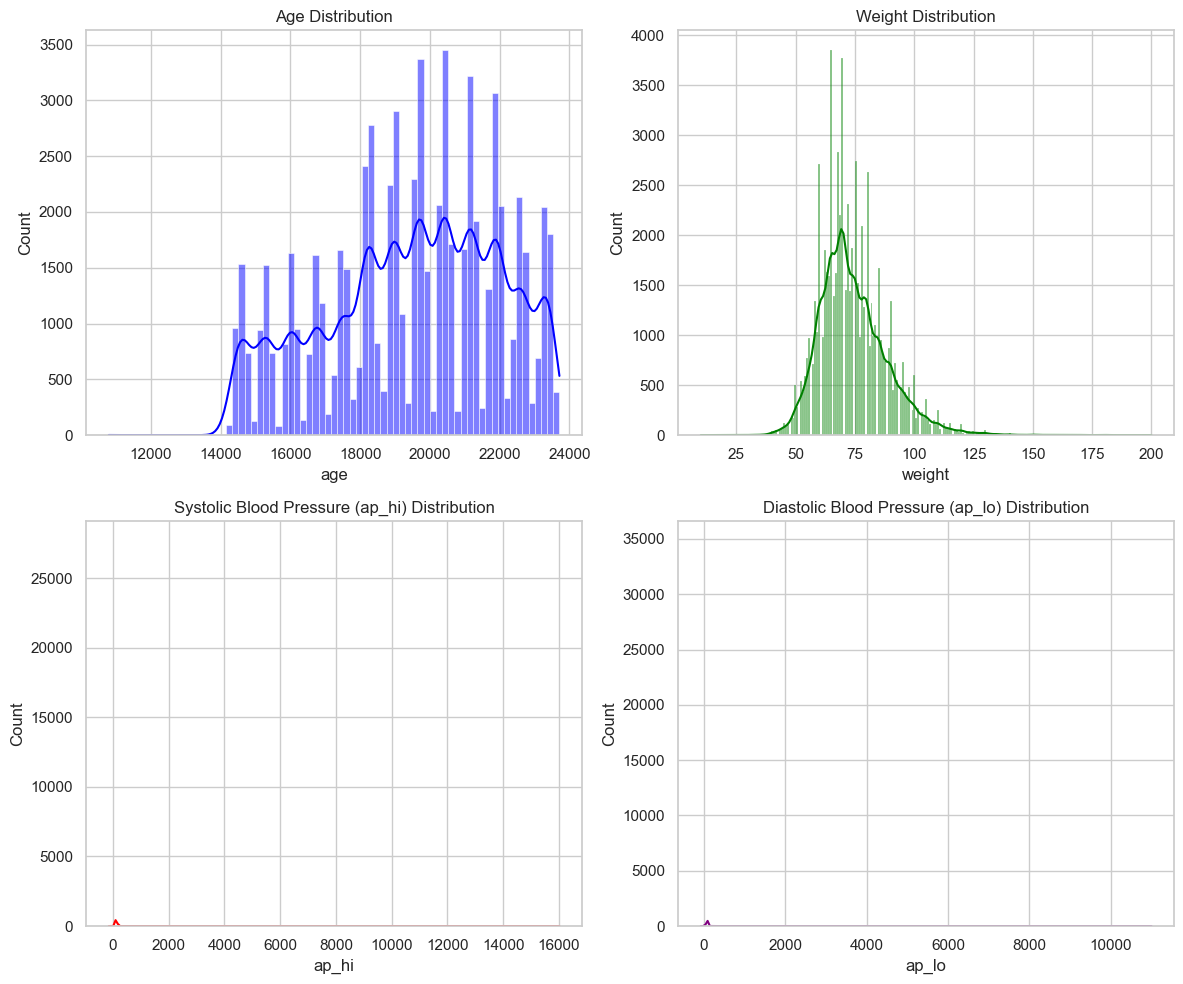

In [8]:

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

sns.histplot(data['age'], kde=True, ax=axes[0, 0], color='blue')
axes[0, 0].set_title('Age Distribution')

sns.histplot(data['weight'], kde=True, ax=axes[0, 1], color='green')
axes[0, 1].set_title('Weight Distribution')

sns.histplot(data['ap_hi'], kde=True, ax=axes[1, 0], color='red')
axes[1, 0].set_title('Systolic Blood Pressure (ap_hi) Distribution')

sns.histplot(data['ap_lo'], kde=True, ax=axes[1, 1], color='purple')
axes[1, 1].set_title('Diastolic Blood Pressure (ap_lo) Distribution')

plt.tight_layout()
plt.show()

In [61]:
X = data.drop(columns=['id', 'cardio','age'])
y = data['cardio']

In [62]:
X.shape

(70000, 10)

In [63]:
scaler = MinMaxScaler()
X_scaled=scaler.fit_transform(X)


In [64]:
X_scaled.shape

(70000, 10)

In [65]:
import joblib
joblib.dump(scaler, 'cardio_model.joblib')

['cardio_model.joblib']

In [66]:
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_scaled, y)

In [67]:
X_res.shape, y_res.value_counts()

((70042, 10),
 cardio
 0    35021
 1    35021
 Name: count, dtype: int64)

In [68]:
X_train, X_test, y_train, y_test = train_test_split(X_res, y_res, test_size=0.2, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((56033, 10), (14009, 10), (56033,), (14009,))

In [49]:
base_models = [
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
    ('xgb', xgb.XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42))
]
meta_model = LogisticRegression()

In [50]:
stacking_model = StackingClassifier(estimators=base_models, final_estimator=meta_model)
stacking_model.fit(X_train, y_train)


c:\Users\1033\.conda\envs\env\lib\site-packages\xgboost\training.py:183: UserWarning: [18:37:39] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\1033\.conda\envs\env\lib\site-packages\xgboost\training.py:183: UserWarning: [18:38:00] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\1033\.conda\envs\env\lib\site-packages\xgboost\training.py:183: UserWarning: [18:38:01] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


StackingClassifier(estimators=[('rf', RandomForestClassifier(random_state=42)),
                               ('xgb',
                                XGBClassifier(base_score=None, booster=None,
                                              callbacks=None,
                                              colsample_bylevel=None,
                                              colsample_bynode=None,
                                              colsample_bytree=None,
                                              device=None,
                                              early_stopping_rounds=None,
                                              enable_categorical=False,
                                              eval_metric='mlogloss',
                                              feature_types=None,
                                              feature_weights=None, gamma=None,
                                              gr...
                                              importance_type=None,
                                              interaction_constraints=None,
                                              learning_rate=None, max_bin=None,
                                              max_cat_threshold=None,
                                              max_cat_to_onehot=None,
                                              max_delta_step=None,
                                              max_depth=None, max_leaves=None,
                                              min_child_weight=None,
                                              missing=nan,
                                              monotone_constraints=None,
                                              multi_strategy=None,
                                              n_estimators=None, n_jobs=None,
                                              num_parallel_tree=None, ...))],
                   final_estimator=LogisticRegression())

In [53]:
stacking_preds = stacking_model.predict(X_test)
stacking_cm = confusion_matrix(y_test, stacking_preds)

In [55]:
stacking_cr = classification_report(y_test, stacking_preds)
print(stacking_cr)

              precision    recall  f1-score   support

           0       0.72      0.78      0.75      6924
           1       0.76      0.71      0.73      7085

    accuracy                           0.74     14009
   macro avg       0.74      0.74      0.74     14009
weighted avg       0.74      0.74      0.74     14009



In [69]:
xgb_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42)
xgb_model.fit(X_train, y_train)

xgb_preds = xgb_model.predict(X_test)


c:\Users\1033\.conda\envs\env\lib\site-packages\xgboost\training.py:183: UserWarning: [18:40:59] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [70]:
X_test.shape

(14009, 10)

In [71]:
joblib.dump(xgb_model, 'xgboost_model.joblib')

['xgboost_model.joblib']

In [72]:
xgb_cm = confusion_matrix(y_test, xgb_preds)

xgb_cr = classification_report(y_test, xgb_preds)
print(xgb_cr)

              precision    recall  f1-score   support

           0       0.70      0.80      0.75      6924
           1       0.77      0.67      0.72      7085

    accuracy                           0.73     14009
   macro avg       0.74      0.73      0.73     14009
weighted avg       0.74      0.73      0.73     14009



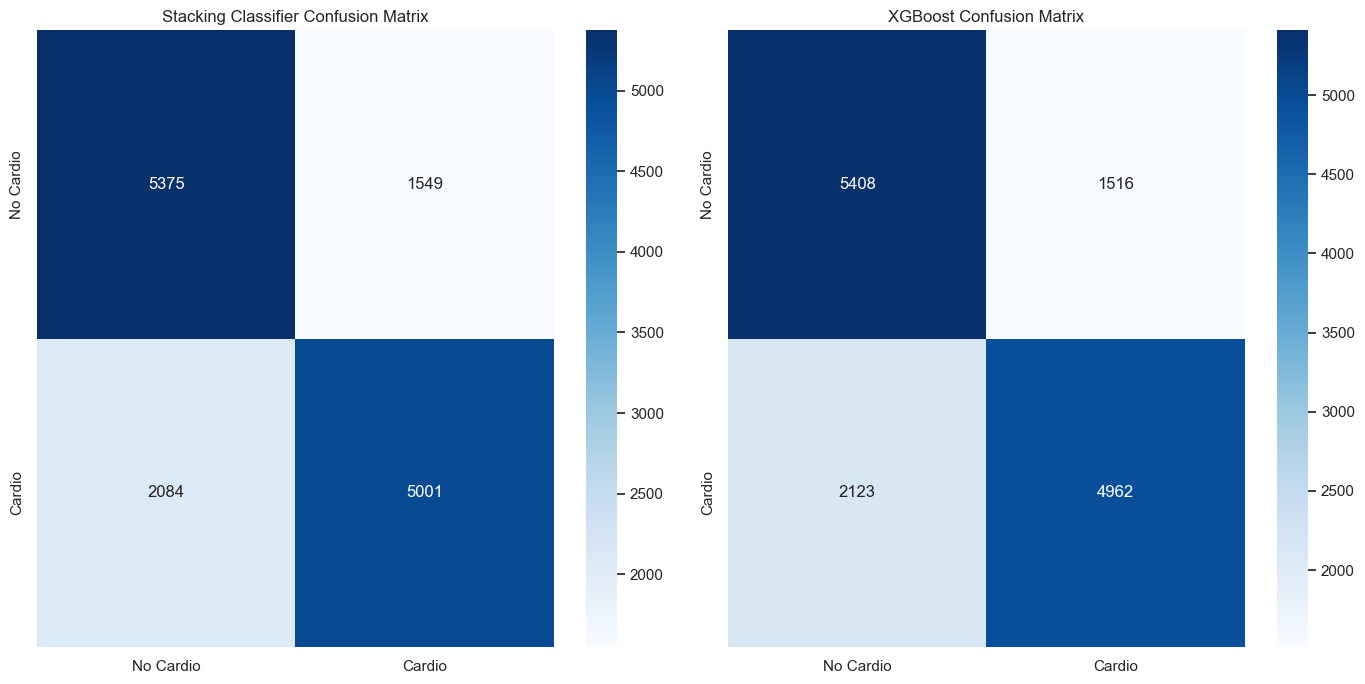

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

sns.heatmap(stacking_cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], xticklabels=['No Cardio', 'Cardio'], yticklabels=['No Cardio', 'Cardio'])
axes[0].set_title('Stacking Classifier Confusion Matrix')

sns.heatmap(xgb_cm, annot=True, fmt='d', cmap='Blues', ax=axes[1], xticklabels=['No Cardio', 'Cardio'], yticklabels=['No Cardio', 'Cardio'])
axes[1].set_title('XGBoost Confusion Matrix')

plt.tight_layout()
plt.show()

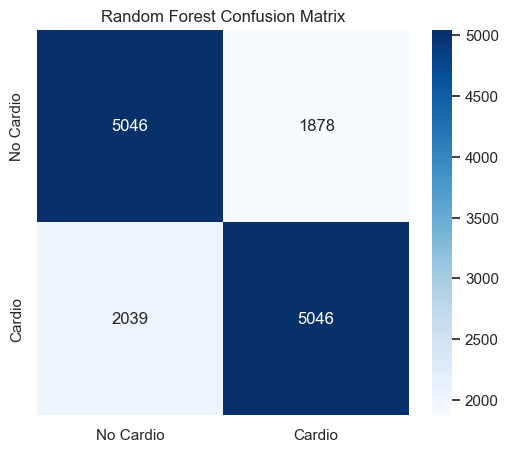

              precision    recall  f1-score   support

           0       0.71      0.73      0.72      6924
           1       0.73      0.71      0.72      7085

    accuracy                           0.72     14009
   macro avg       0.72      0.72      0.72     14009
weighted avg       0.72      0.72      0.72     14009



In [20]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

rf_preds = rf_model.predict(X_test)

rf_cm = confusion_matrix(y_test, rf_preds)
rf_cr = classification_report(y_test, rf_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(rf_cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Cardio', 'Cardio'], yticklabels=['No Cardio', 'Cardio'])
plt.title('Random Forest Confusion Matrix')
plt.show()

print(rf_cr)


In [41]:
X_train_cnn = X_train.values.reshape(-1, X_train.shape[1], 1)
X_test_cnn = X_test.values.reshape(-1, X_test.shape[1], 1)

In [ ]:


cnn_model = models.Sequential()

cnn_model.add(layers.Conv1D(32, 3, activation='relu', input_shape=(X_train_cnn.shape[1], 1)))
cnn_model.add(layers.MaxPooling1D(2))

cnn_model.add(layers.Conv1D(64, 3, activation='relu'))
cnn_model.add(layers.MaxPooling1D(2))
cnn_model.add(layers.Flatten())

cnn_model.add(layers.Dense(128, activation='relu'))
cnn_model.add(layers.Dense(1, activation='sigmoid'))

cnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

cnn_history = cnn_model.fit(X_train_cnn, y_train, epochs=10, batch_size=32, validation_data=(X_test_cnn, y_test))




Epoch 1/10


C:\Users\0871\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1752/1752 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6026 - loss: 0.6585 - val_accuracy: 0.6191 - val_loss: 0.6542
Epoch 2/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6340 - loss: 0.6359 - val_accuracy: 0.6442 - val_loss: 0.6325
Epoch 3/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6425 - loss: 0.6312 - val_accuracy: 0.6420 - val_loss: 0.6317
Epoch 4/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6443 - loss: 0.6296 - val_accuracy: 0.6439 - val_loss: 0.6292
Epoch 5/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6432 - loss: 0.6295 - val_accuracy: 0.6459 - val_loss: 0.6297
Epoch 6/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6412 - loss: 0.6314 - val_accuracy: 0.6445 - val_loss: 0.6277
Epoch 7/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6466 - loss: 0.6288 - val_accuracy: 0.6417 - val_loss: 0.6330
Epoch 8/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6398 - loss: 0.6317 - val_accurac

In [43]:
# Evaluate the CNN model on the test set
cnn_test_loss, cnn_test_acc = cnn_model.evaluate(X_test_cnn, y_test)

cnn_test_acc, cnn_test_loss

438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 800us/step - accuracy: 0.6552 - loss: 0.6215


(0.6547933220863342, 0.6199554204940796)

438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 722us/step


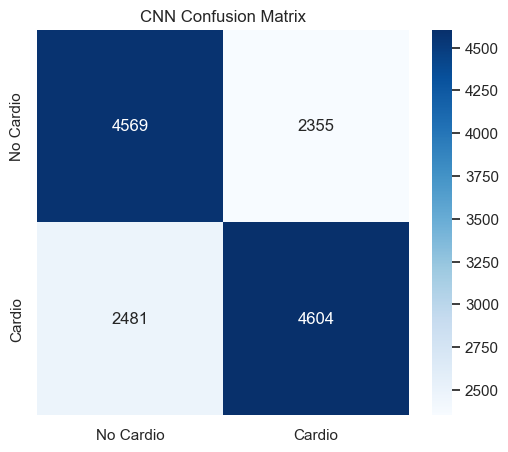

              precision    recall  f1-score   support

           0       0.65      0.66      0.65      6924
           1       0.66      0.65      0.66      7085

    accuracy                           0.65     14009
   macro avg       0.65      0.65      0.65     14009
weighted avg       0.65      0.65      0.65     14009



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Make predictions with CNN
cnn_preds = cnn_model.predict(X_test_cnn)
cnn_preds = (cnn_preds > 0.5).astype(int) 

cnn_cm = confusion_matrix(y_test, cnn_preds)

cnn_cr = classification_report(y_test, cnn_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(cnn_cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Cardio', 'Cardio'], yticklabels=['No Cardio', 'Cardio'])
plt.title('CNN Confusion Matrix')
plt.show()

print(cnn_cr)


In [45]:
X_train_lstm = X_train.values.reshape(-1, 1, X_train.shape[1]) 
X_test_lstm = X_test.values.reshape(-1, 1, X_test.shape[1])  

In [ ]:

lstm_model = models.Sequential()
lstm_model.add(layers.LSTM(64, activation='relu', input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])))
lstm_model.add(layers.Dense(64, activation='relu'))
lstm_model.add(layers.Dense(1, activation='sigmoid'))

lstm_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
lstm_history = lstm_model.fit(X_train_lstm, y_train, epochs=10, batch_size=32, validation_data=(X_test_lstm, y_test))





Epoch 1/10


C:\Users\0871\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1752/1752 ━━━━━━━━━━━━━━━━━━━━ 3s 973us/step - accuracy: 0.5945 - loss: 0.6600 - val_accuracy: 0.6290 - val_loss: 0.6414
Epoch 2/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 2s 879us/step - accuracy: 0.6364 - loss: 0.6343 - val_accuracy: 0.6475 - val_loss: 0.6259
Epoch 3/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 2s 910us/step - accuracy: 0.6433 - loss: 0.6282 - val_accuracy: 0.6374 - val_loss: 0.6332
Epoch 4/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 2s 897us/step - accuracy: 0.6477 - loss: 0.6271 - val_accuracy: 0.6452 - val_loss: 0.6252
Epoch 5/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 2s 911us/step - accuracy: 0.6452 - loss: 0.6293 - val_accuracy: 0.6522 - val_loss: 0.6230
Epoch 6/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 2s 908us/step - accuracy: 0.6495 - loss: 0.6233 - val_accuracy: 0.6519 - val_loss: 0.6217
Epoch 7/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 2s 909us/step - accuracy: 0.6520 - loss: 0.6250 - val_accuracy: 0.6541 - val_loss: 0.6195
Epoch 8/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 2s 905us/step - accuracy: 0.6494 - loss: 0.62

In [47]:
lstm_test_loss, lstm_test_acc = lstm_model.evaluate(X_test_lstm, y_test)

lstm_test_acc, lstm_test_loss

438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 578us/step - accuracy: 0.6559 - loss: 0.6199


(0.6573631167411804, 0.6184177994728088)

In [48]:

lstm_preds = lstm_model.predict(X_test_lstm)
lstm_preds = (lstm_preds > 0.5).astype(int)  

438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 575us/step


In [49]:
lstm_cm = confusion_matrix(y_test, lstm_preds)
lstm_cr = classification_report(y_test, lstm_preds)

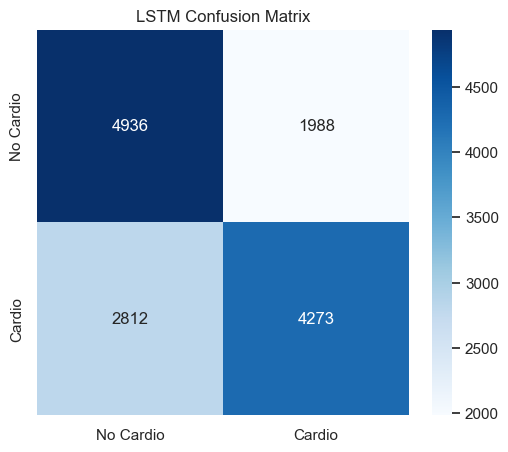

In [50]:
plt.figure(figsize=(6, 5))
sns.heatmap(lstm_cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Cardio', 'Cardio'], yticklabels=['No Cardio', 'Cardio'])
plt.title('LSTM Confusion Matrix')
plt.show()


In [51]:
print(lstm_cr)

              precision    recall  f1-score   support

           0       0.64      0.71      0.67      6924
           1       0.68      0.60      0.64      7085

    accuracy                           0.66     14009
   macro avg       0.66      0.66      0.66     14009
weighted avg       0.66      0.66      0.66     14009



In [ ]:

X_train_rnn = X_train.values.reshape(-1, 1, X_train.shape[1])  
X_test_rnn = X_test.values.reshape(-1, 1, X_test.shape[1])  

rnn_model = models.Sequential()

rnn_model.add(layers.SimpleRNN(64, activation='relu', input_shape=(X_train_rnn.shape[1], X_train_rnn.shape[2])))
rnn_model.add(layers.Dense(64, activation='relu'))

rnn_model.add(layers.Dense(1, activation='sigmoid'))

rnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

rnn_history = rnn_model.fit(X_train_rnn, y_train, epochs=10, batch_size=32, validation_data=(X_test_rnn, y_test))

rnn_test_loss, rnn_test_acc = rnn_model.evaluate(X_test_rnn, y_test)

rnn_test_acc, rnn_test_loss


Epoch 1/10


C:\Users\0871\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1752/1752 ━━━━━━━━━━━━━━━━━━━━ 2s 899us/step - accuracy: 0.6046 - loss: 0.6554 - val_accuracy: 0.6429 - val_loss: 0.6306
Epoch 2/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 1s 813us/step - accuracy: 0.6396 - loss: 0.6322 - val_accuracy: 0.6494 - val_loss: 0.6271
Epoch 3/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 1s 828us/step - accuracy: 0.6392 - loss: 0.6344 - val_accuracy: 0.6529 - val_loss: 0.6242
Epoch 4/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 1s 823us/step - accuracy: 0.6465 - loss: 0.6287 - val_accuracy: 0.6318 - val_loss: 0.6361
Epoch 5/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 1s 812us/step - accuracy: 0.6453 - loss: 0.6273 - val_accuracy: 0.6419 - val_loss: 0.6270
Epoch 6/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 1s 815us/step - accuracy: 0.6465 - loss: 0.6279 - val_accuracy: 0.6531 - val_loss: 0.6226
Epoch 7/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 1s 816us/step - accuracy: 0.6489 - loss: 0.6242 - val_accuracy: 0.6547 - val_loss: 0.6210
Epoch 8/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 1s 825us/step - accuracy: 0.6524 - loss: 0.62

(0.653222918510437, 0.6187121272087097)

438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 520us/step


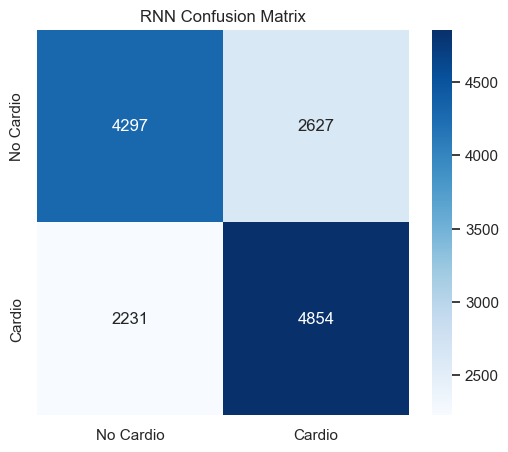

              precision    recall  f1-score   support

           0       0.66      0.62      0.64      6924
           1       0.65      0.69      0.67      7085

    accuracy                           0.65     14009
   macro avg       0.65      0.65      0.65     14009
weighted avg       0.65      0.65      0.65     14009



In [ ]:
rnn_preds = rnn_model.predict(X_test_rnn)
rnn_preds = (rnn_preds > 0.5).astype(int)  

rnn_cm = confusion_matrix(y_test, rnn_preds)

rnn_cr = classification_report(y_test, rnn_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(rnn_cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Cardio', 'Cardio'], yticklabels=['No Cardio', 'Cardio'])
plt.title('RNN Confusion Matrix')
plt.show()

print(rnn_cr)


In [54]:



X_train_gru = X_train.values.reshape(-1, 1, X_train.shape[1])  
X_test_gru = X_test.values.reshape(-1, 1, X_test.shape[1]) 
gru_model = models.Sequential()

gru_model.add(layers.GRU(64, activation='relu', input_shape=(X_train_gru.shape[1], X_train_gru.shape[2])))

gru_model.add(layers.Dense(64, activation='relu'))

gru_model.add(layers.Dense(1, activation='sigmoid'))

gru_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

gru_history = gru_model.fit(X_train_gru, y_train, epochs=10, batch_size=32, validation_data=(X_test_gru, y_test))

gru_test_loss, gru_test_acc = gru_model.evaluate(X_test_gru, y_test)

gru_test_acc, gru_test_loss


Epoch 1/10


C:\Users\0871\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1752/1752 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.6035 - loss: 0.6564 - val_accuracy: 0.6431 - val_loss: 0.6294
Epoch 2/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 2s 968us/step - accuracy: 0.6424 - loss: 0.6314 - val_accuracy: 0.6435 - val_loss: 0.6279
Epoch 3/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 2s 944us/step - accuracy: 0.6435 - loss: 0.6307 - val_accuracy: 0.6532 - val_loss: 0.6222
Epoch 4/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 2s 946us/step - accuracy: 0.6439 - loss: 0.6291 - val_accuracy: 0.6500 - val_loss: 0.6255
Epoch 5/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 2s 949us/step - accuracy: 0.6475 - loss: 0.6261 - val_accuracy: 0.6459 - val_loss: 0.6305
Epoch 6/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 2s 950us/step - accuracy: 0.6476 - loss: 0.6263 - val_accuracy: 0.6514 - val_loss: 0.6208
Epoch 7/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 2s 945us/step - accuracy: 0.6500 - loss: 0.6244 - val_accuracy: 0.6549 - val_loss: 0.6193
Epoch 8/10
1752/1752 ━━━━━━━━━━━━━━━━━━━━ 2s 944us/step - accuracy: 0.6492 - loss: 0.6245

(0.654222309589386, 0.6186459064483643)

438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 647us/step


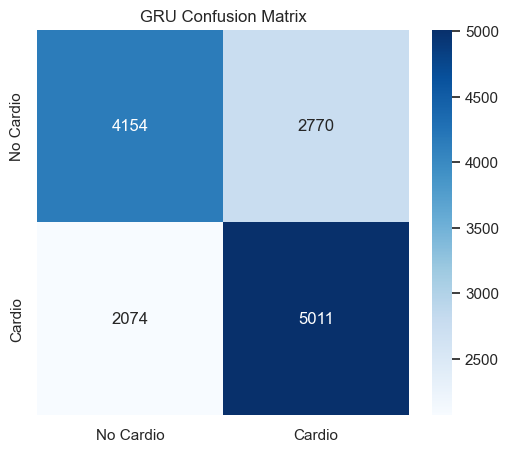

              precision    recall  f1-score   support

           0       0.67      0.60      0.63      6924
           1       0.64      0.71      0.67      7085

    accuracy                           0.65     14009
   macro avg       0.66      0.65      0.65     14009
weighted avg       0.66      0.65      0.65     14009



In [ ]:

gru_preds = gru_model.predict(X_test_gru)
gru_preds = (gru_preds > 0.5).astype(int) 
gru_cm = confusion_matrix(y_test, gru_preds)

gru_cr = classification_report(y_test, gru_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(gru_cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Cardio', 'Cardio'], yticklabels=['No Cardio', 'Cardio'])
plt.title('GRU Confusion Matrix')
plt.show()

print(gru_cr)


In [ ]:
import joblib
import numpy as np

# ✅ Step 1: Load the saved model and scaler
xgb_model = joblib.load('xgboost_model.joblib')
scaler = joblib.load('cardio_model.joblib') # Load only the scaler part from the saved joblib

# Input values
input_data = {
    
    'gender': 1,  # 1 for male, 0 for female (assuming binary encoding)
    'height': 165,
    'weight': 78,
    'ap_hi': 140,  # Systolic BP
    'ap_lo': 90,   # Diastolic BP
    'cholesterol': 1,  # 1: normal, 2: above normal, 3: well above normal
    'gluc': 1,  # 1: normal, 2: above normal, 3: well above normal
    'smoke': 0,  # 1: yes, 0: no
    'alco': 0,   # 1: yes, 0: no
    'active': 1  # 1: yes, 0: no
}

# ✅ Step 2: Prepare input data as an array (reshape for prediction)
input_array = np.array([
   input_data['gender'], input_data['height'], input_data['weight'],
    input_data['ap_hi'], input_data['ap_lo'], input_data['cholesterol'], input_data['gluc'],
    input_data['smoke'], input_data['alco'], input_data['active']
]).reshape(1, -1)  # Reshape to 2D array for prediction

# ✅ Step 3: Scale the input data using the same scaler used during training
input_scaled = scaler.transform(input_array)

# ✅ Step 4: Make prediction
prediction = xgb_model.predict(input_scaled)

# ✅ Step 5: Output the prediction
if prediction[0] == 0:
    print("Prediction: No Cardiovascular Disease Detected")
else:
    print("Prediction: Risk of Cardiovascular Disease")


Prediction: Risk of Cardiovascular Disease


c:\Users\1033\.conda\envs\env\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
